# Digital Image Processing – Assignment 2
**Name:** Abisha
**ID:** 232031056

Image shape: (512, 512) dtype: uint8


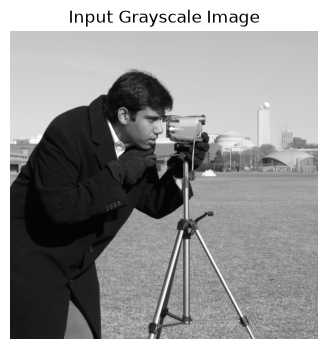

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import urllib.request

REPO_IMG_BASE = "https://raw.githubusercontent.com/id-232031056/dip/main/images"

def load_image(filename, gray=False):
    url = f"{REPO_IMG_BASE}/{filename}"
    try:
        resp = urllib.request.urlopen(url, timeout=10)
        arr = np.asarray(bytearray(resp.read()), dtype=np.uint8)
        flag = cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR
        img = cv2.imdecode(arr, flag)
        if img is not None:
            if not gray:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            return img
    except Exception:
        pass
    from skimage import data
    if gray:
        return data.camera()
    return data.astronaut()

img_gray = load_image("test_gray.png", gray=True)
print("Image shape:", img_gray.shape, "dtype:", img_gray.dtype)
plt.figure(figsize=(5, 4)); plt.imshow(img_gray, cmap='gray'); plt.title("Input Grayscale Image"); plt.axis('off'); plt.show()

## Task 2.1 – Linear Transformations

Linear intensity transformations apply a function s = T(r) to each pixel:
- **Negative/Inverse**: s = (L−1) − r, where L = 256. Reverses the intensity range.
- **Brightness/Contrast**: s = α·r + β, where α controls contrast and β controls brightness.
- **Piecewise-linear contrast stretching**: maps a sub-range [r1, r2] to [s1, s2] to enhance specific intensity bands.

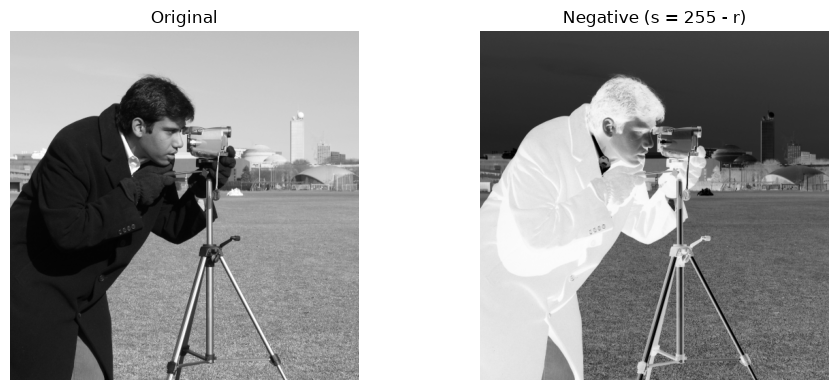

In [2]:
# --- Negative / Inverse ---
def negative_transform(image):
    """Compute the negative of a grayscale image: s = 255 - r."""
    return 255 - image

neg_img = negative_transform(img_gray)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_gray, cmap='gray'); axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(neg_img, cmap='gray'); axes[1].set_title("Negative (s = 255 - r)"); axes[1].axis('off')
plt.tight_layout(); plt.show()

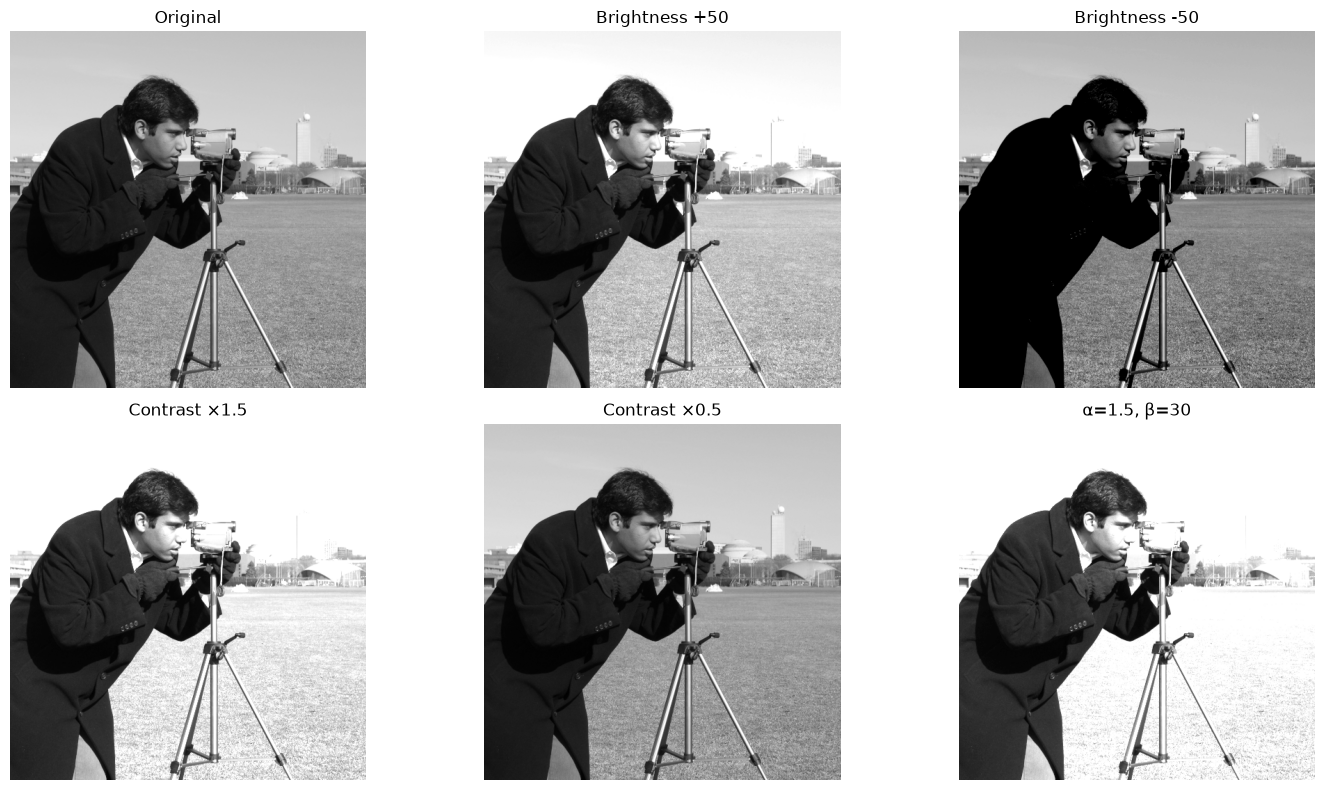

In [3]:
# --- Brightness and Contrast Adjustment ---
def brightness_contrast(image, alpha=1.0, beta=0):
    """Apply brightness/contrast: s = alpha * r + beta. Clip to [0, 255]."""
    result = np.clip(alpha * image.astype(np.float64) + beta, 0, 255)
    return result.astype(np.uint8)

# Several combinations
configs = [
    (1.0, 50, "Brightness +50"),
    (1.0, -50, "Brightness -50"),
    (1.5, 0, "Contrast ×1.5"),
    (0.5, 0, "Contrast ×0.5"),
    (1.5, 30, "α=1.5, β=30"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].imshow(img_gray, cmap='gray'); axes[0, 0].set_title("Original"); axes[0, 0].axis('off')
for idx, (a, b, title) in enumerate(configs):
    r, col = (idx + 1) // 3, (idx + 1) % 3
    result = brightness_contrast(img_gray, a, b)
    axes[r, col].imshow(result, cmap='gray'); axes[r, col].set_title(title); axes[r, col].axis('off')
plt.tight_layout(); plt.show()

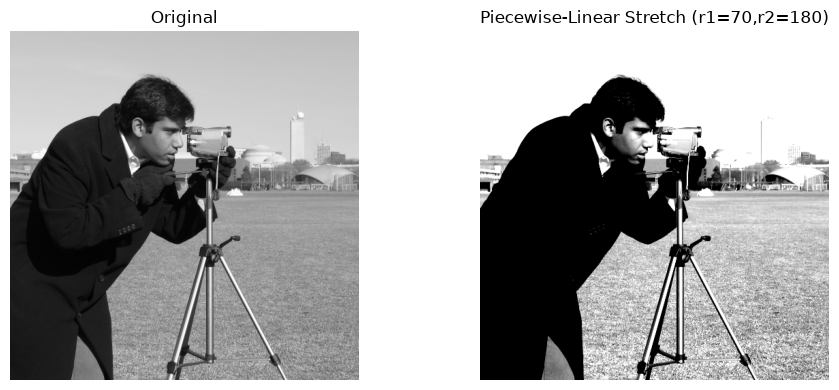

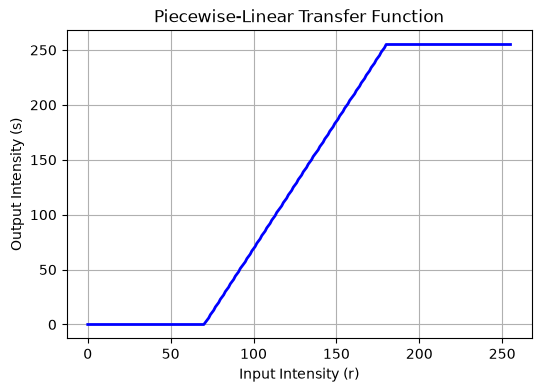

In [4]:
# --- Piecewise-Linear Contrast Stretching ---
def piecewise_linear_stretch(image, r1, s1, r2, s2):
    """Apply piecewise-linear contrast stretching.
    Three segments: [0,r1]->[0,s1], [r1,r2]->[s1,s2], [r2,255]->[s2,255]."""
    out = np.zeros_like(image, dtype=np.float64)
    # Segment 1: 0 to r1
    mask1 = image <= r1
    if r1 > 0:
        out[mask1] = (s1 / r1) * image[mask1]
    # Segment 2: r1 to r2
    mask2 = (image > r1) & (image <= r2)
    if r2 > r1:
        out[mask2] = s1 + ((s2 - s1) / (r2 - r1)) * (image[mask2] - r1)
    # Segment 3: r2 to 255
    mask3 = image > r2
    if 255 > r2:
        out[mask3] = s2 + ((255 - s2) / (255 - r2)) * (image[mask3] - r2)
    return np.clip(out, 0, 255).astype(np.uint8)

stretched = piecewise_linear_stretch(img_gray, r1=70, s1=0, r2=180, s2=255)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_gray, cmap='gray'); axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(stretched, cmap='gray'); axes[1].set_title("Piecewise-Linear Stretch (r1=70,r2=180)"); axes[1].axis('off')
plt.tight_layout(); plt.show()

# Show the transfer function
r_vals = np.arange(256)
s_vals = piecewise_linear_stretch(r_vals.reshape(1,-1), 70, 0, 180, 255).ravel()
plt.figure(figsize=(6, 4))
plt.plot(r_vals, s_vals, 'b-', linewidth=2)
plt.xlabel("Input Intensity (r)"); plt.ylabel("Output Intensity (s)")
plt.title("Piecewise-Linear Transfer Function"); plt.grid(True)
plt.show()

## Task 2.2 – Non-Linear Transformations

- **Log transformation**: s = c · log(1 + r), where c = 255 / log(1 + max_val). Expands dark intensities and compresses bright ones.
- **Power-law (Gamma) transformation**: s = c · r^γ, where c = 255 / (255^γ). γ < 1 brightens, γ > 1 darkens the image.

/var/folders/lt/n44ctb8n56sgw3vlfcv_8_w40000gn/T/ipykernel_20390/740722227.py:4: RuntimeWarning: overflow encountered in scalar add
  c = 255.0 / np.log(1 + image.max())
/var/folders/lt/n44ctb8n56sgw3vlfcv_8_w40000gn/T/ipykernel_20390/740722227.py:4: RuntimeWarning: divide by zero encountered in log
  c = 255.0 / np.log(1 + image.max())


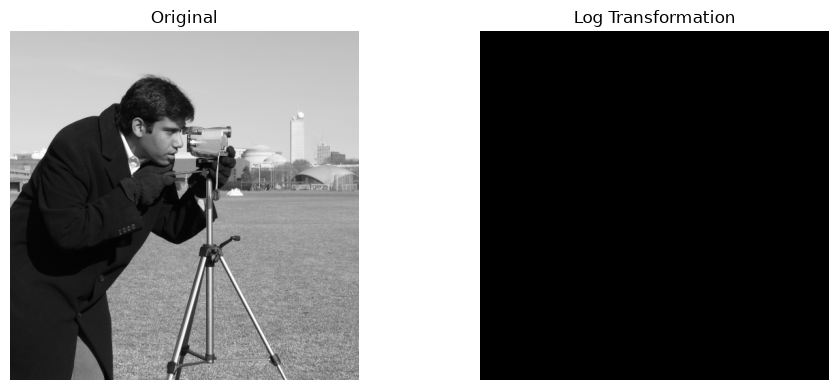

In [5]:
# --- Log Transformation ---
def log_transform(image):
    """Apply log transformation: s = c * log(1 + r)."""
    c = 255.0 / np.log(1 + image.max())
    result = c * np.log(1.0 + image.astype(np.float64))
    return np.clip(result, 0, 255).astype(np.uint8)

log_img = log_transform(img_gray)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_gray, cmap='gray'); axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(log_img, cmap='gray'); axes[1].set_title("Log Transformation"); axes[1].axis('off')
plt.tight_layout(); plt.show()

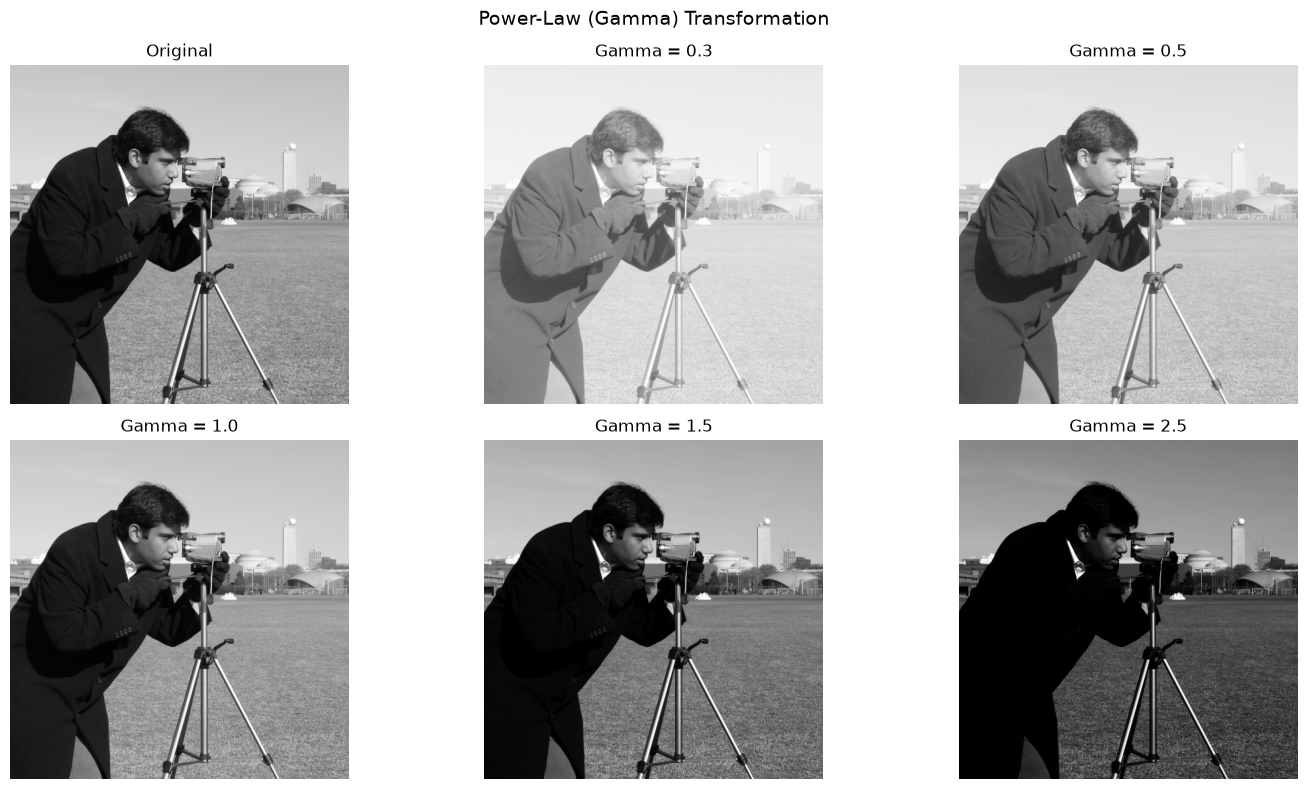

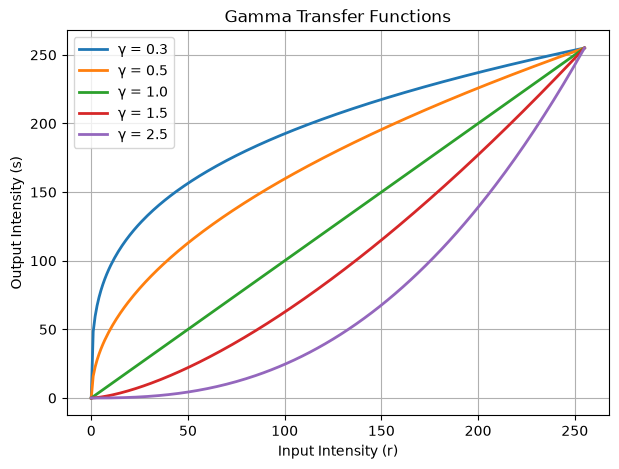

In [6]:
# --- Power-Law (Gamma) Transformation ---
def gamma_transform(image, gamma):
    """Apply power-law transformation: s = c * r^gamma. Normalise to [0,1] first."""
    normalised = image.astype(np.float64) / 255.0
    result = np.power(normalised, gamma) * 255.0
    return np.clip(result, 0, 255).astype(np.uint8)

gammas = [0.3, 0.5, 1.0, 1.5, 2.5]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].imshow(img_gray, cmap='gray'); axes[0, 0].set_title("Original"); axes[0, 0].axis('off')
for idx, g in enumerate(gammas):
    r, col = (idx + 1) // 3, (idx + 1) % 3
    result = gamma_transform(img_gray, g)
    axes[r, col].imshow(result, cmap='gray')
    axes[r, col].set_title(f"Gamma = {g}")
    axes[r, col].axis('off')
plt.suptitle("Power-Law (Gamma) Transformation", fontsize=14)
plt.tight_layout(); plt.show()

# Show transfer functions
plt.figure(figsize=(7, 5))
r_vals = np.arange(256)
for g in gammas:
    s_vals = np.power(r_vals / 255.0, g) * 255.0
    plt.plot(r_vals, s_vals, label=f'γ = {g}', linewidth=2)
plt.xlabel("Input Intensity (r)"); plt.ylabel("Output Intensity (s)")
plt.title("Gamma Transfer Functions"); plt.legend(); plt.grid(True)
plt.show()

## Task 2.3 – Image Thresholding

Thresholding converts a grayscale image to binary by comparing each pixel to a threshold T:
- s = 255 if r ≥ T, else s = 0 (global thresholding).
- **Otsu's method** automatically finds the optimal threshold T that minimises within-class variance.

Note: This task focuses on thresholding as an intensity transformation, not on segmentation.

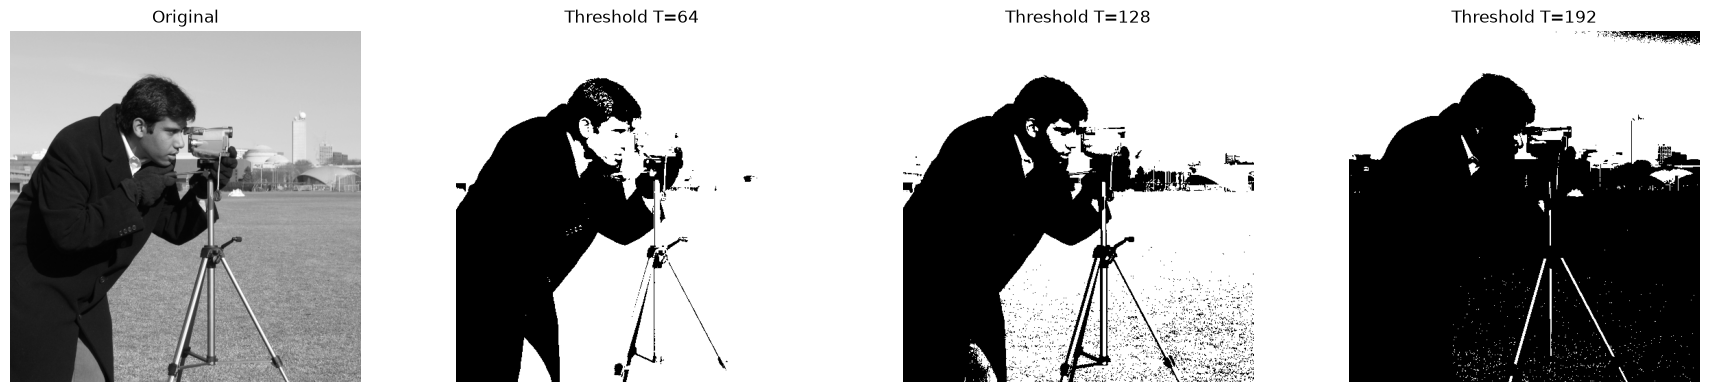

In [7]:
# --- Global Thresholding ---
def global_threshold(image, T):
    """Apply global thresholding: binary image at threshold T."""
    return np.where(image >= T, 255, 0).astype(np.uint8)

thresholds = [64, 128, 192]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(img_gray, cmap='gray'); axes[0].set_title("Original"); axes[0].axis('off')
for i, T in enumerate(thresholds):
    binary = global_threshold(img_gray, T)
    axes[i+1].imshow(binary, cmap='gray'); axes[i+1].set_title(f"Threshold T={T}"); axes[i+1].axis('off')
plt.tight_layout(); plt.show()

Otsu threshold (manual): 102
Otsu threshold (OpenCV): 102.0


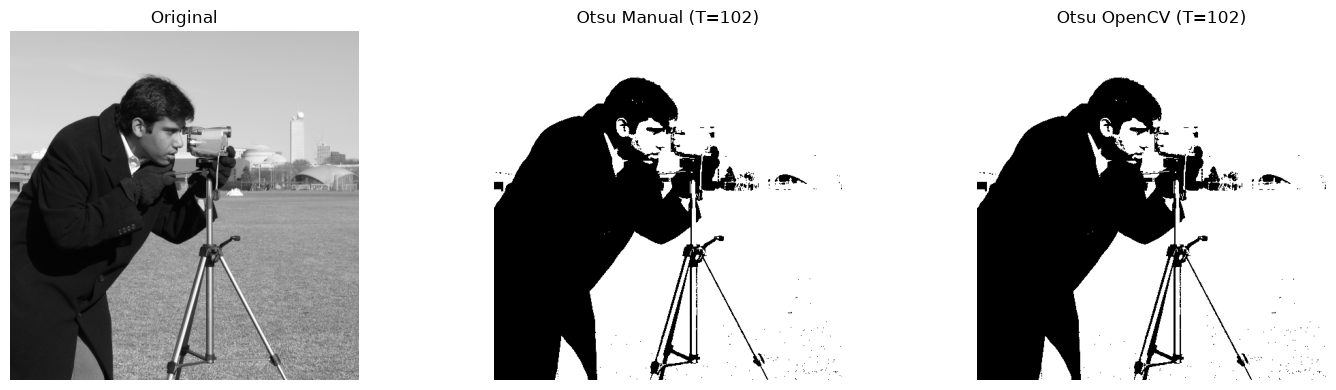

In [8]:
# --- Otsu's Method (manual implementation) ---
def otsu_threshold(image):
    """Compute optimal threshold using Otsu's method (manual)."""
    hist = np.zeros(256)
    for val in image.ravel():
        hist[val] += 1
    total = image.size
    prob = hist / total

    best_T = 0
    best_var = 0

    for T in range(256):
        # Class probabilities
        w0 = prob[:T+1].sum()
        w1 = prob[T+1:].sum()
        if w0 == 0 or w1 == 0:
            continue
        # Class means
        mu0 = np.sum(np.arange(T+1) * prob[:T+1]) / w0
        mu1 = np.sum(np.arange(T+1, 256) * prob[T+1:]) / w1
        # Between-class variance
        var_between = w0 * w1 * (mu0 - mu1) ** 2
        if var_between > best_var:
            best_var = var_between
            best_T = T

    return best_T

T_otsu_manual = otsu_threshold(img_gray)
T_otsu_cv2, _ = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print(f"Otsu threshold (manual): {T_otsu_manual}")
print(f"Otsu threshold (OpenCV): {T_otsu_cv2}")

binary_otsu = global_threshold(img_gray, T_otsu_manual)
_, binary_cv2 = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_gray, cmap='gray'); axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(binary_otsu, cmap='gray'); axes[1].set_title(f"Otsu Manual (T={T_otsu_manual})"); axes[1].axis('off')
axes[2].imshow(binary_cv2, cmap='gray'); axes[2].set_title(f"Otsu OpenCV (T={int(T_otsu_cv2)})"); axes[2].axis('off')
plt.tight_layout(); plt.show()

## Task 2.4 – Bit-Plane Slicing

Each pixel in an 8-bit grayscale image can be decomposed into 8 bit-planes (bits 0–7).
Bit-plane k is extracted as: plane_k = (pixel >> k) & 1.
The most significant bit-planes (7, 6, 5) carry most of the visual information.
Reconstruction using only the top N planes: reconstructed = Σ (plane_k × 2^k) for k in selected planes.

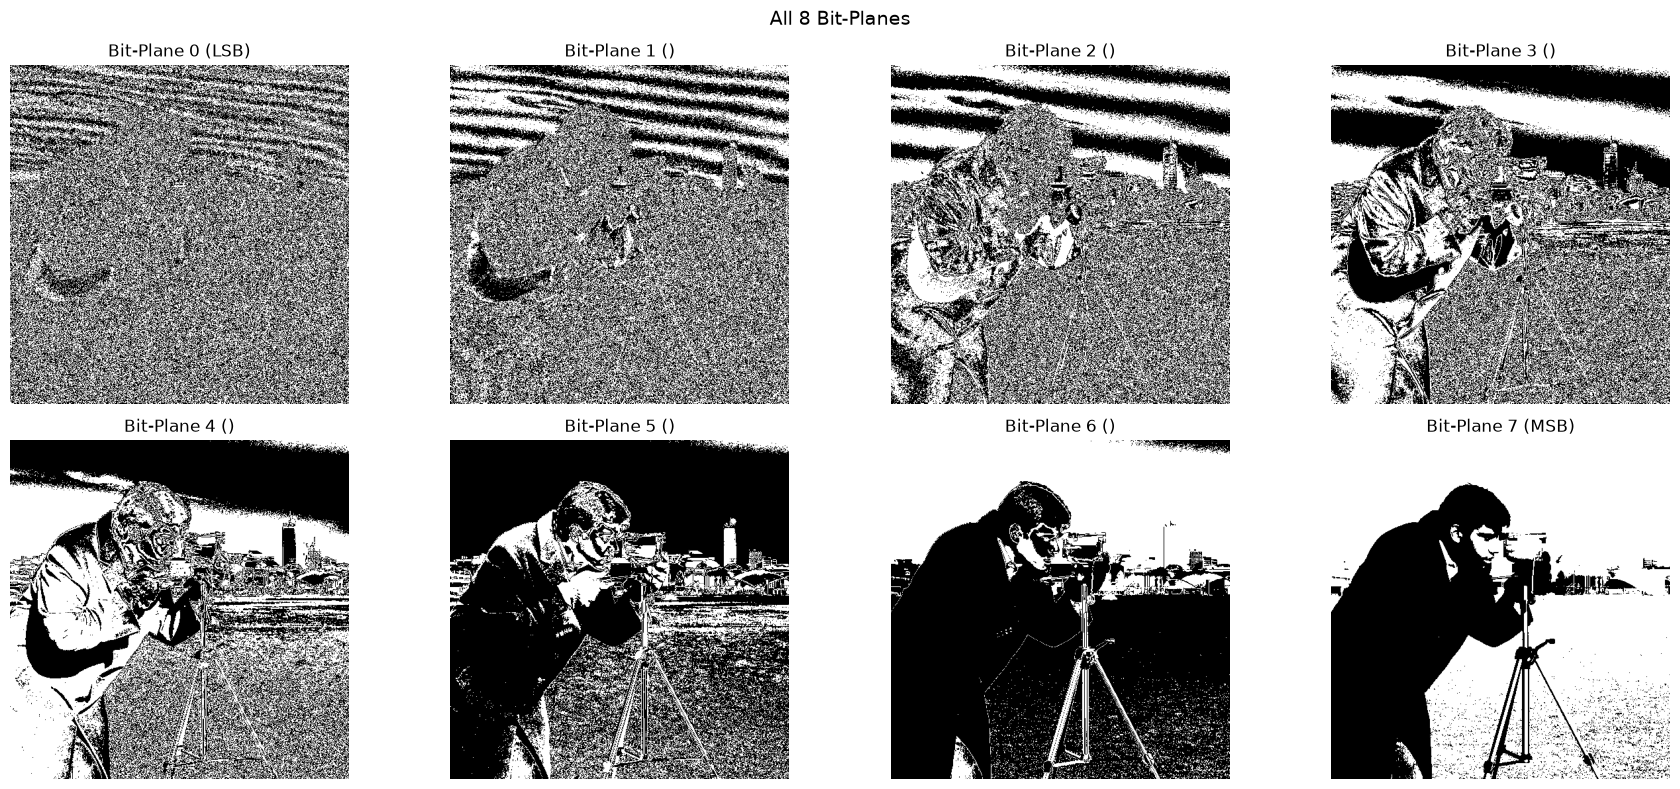

In [9]:
def extract_bit_planes(image):
    """Extract all 8 bit-planes of a grayscale image."""
    planes = []
    for k in range(8):
        plane = ((image >> k) & 1).astype(np.uint8) * 255  # scale to 0/255 for display
        planes.append(plane)
    return planes

planes = extract_bit_planes(img_gray)

# Display all 8 bit-planes
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for k in range(8):
    r, col = k // 4, k % 4
    axes[r, col].imshow(planes[k], cmap='gray')
    axes[r, col].set_title(f"Bit-Plane {k} ({'MSB' if k==7 else 'LSB' if k==0 else ''})")
    axes[r, col].axis('off')
plt.suptitle("All 8 Bit-Planes", fontsize=14)
plt.tight_layout(); plt.show()

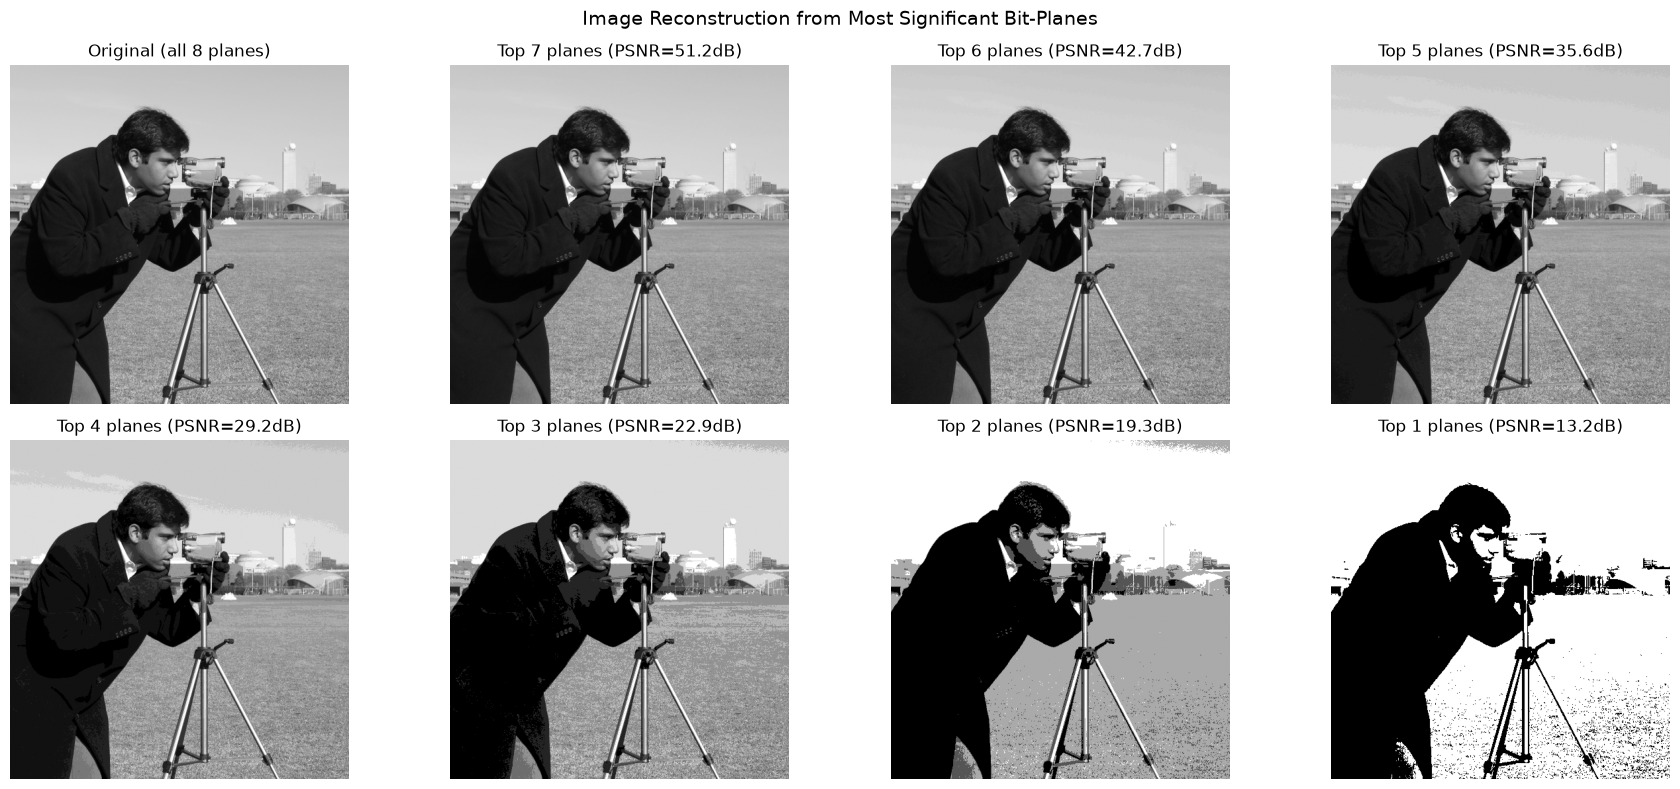

In [10]:
# Reconstruction using most significant bit-planes
def reconstruct_from_planes(image, num_top_planes):
    """Reconstruct image using only the top N most significant bit-planes."""
    result = np.zeros_like(image, dtype=np.uint8)
    for k in range(8 - num_top_planes, 8):
        bit = ((image >> k) & 1).astype(np.uint8)
        result = result + (bit << k)
    return result

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes[0, 0].imshow(img_gray, cmap='gray'); axes[0, 0].set_title("Original (all 8 planes)"); axes[0, 0].axis('off')

for idx, n_planes in enumerate([7, 6, 5, 4, 3, 2, 1]):
    r, col = (idx + 1) // 4, (idx + 1) % 4
    recon = reconstruct_from_planes(img_gray, n_planes)
    psnr = 10 * np.log10(255**2 / (np.mean((img_gray.astype(float) - recon.astype(float))**2) + 1e-10))
    axes[r, col].imshow(recon, cmap='gray')
    axes[r, col].set_title(f"Top {n_planes} planes (PSNR={psnr:.1f}dB)")
    axes[r, col].axis('off')

plt.suptitle("Image Reconstruction from Most Significant Bit-Planes", fontsize=14)
plt.tight_layout(); plt.show()

## Conclusion

In this assignment, we explored several intensity transformation techniques:

1. **Linear Transformations** (Task 2.1): Negative, brightness/contrast adjustment, and piecewise-linear contrast stretching — all straightforward mappings of pixel intensities.
2. **Non-Linear Transformations** (Task 2.2): Log and power-law (gamma) transforms provide non-linear intensity mappings useful for enhancing dark or bright regions selectively.
3. **Thresholding** (Task 2.3): Global thresholding and Otsu's automatic threshold selection convert grayscale images to binary.
4. **Bit-Plane Slicing** (Task 2.4): Decomposing images into bit-planes reveals that the most significant planes carry the majority of visual information, enabling efficient representation.